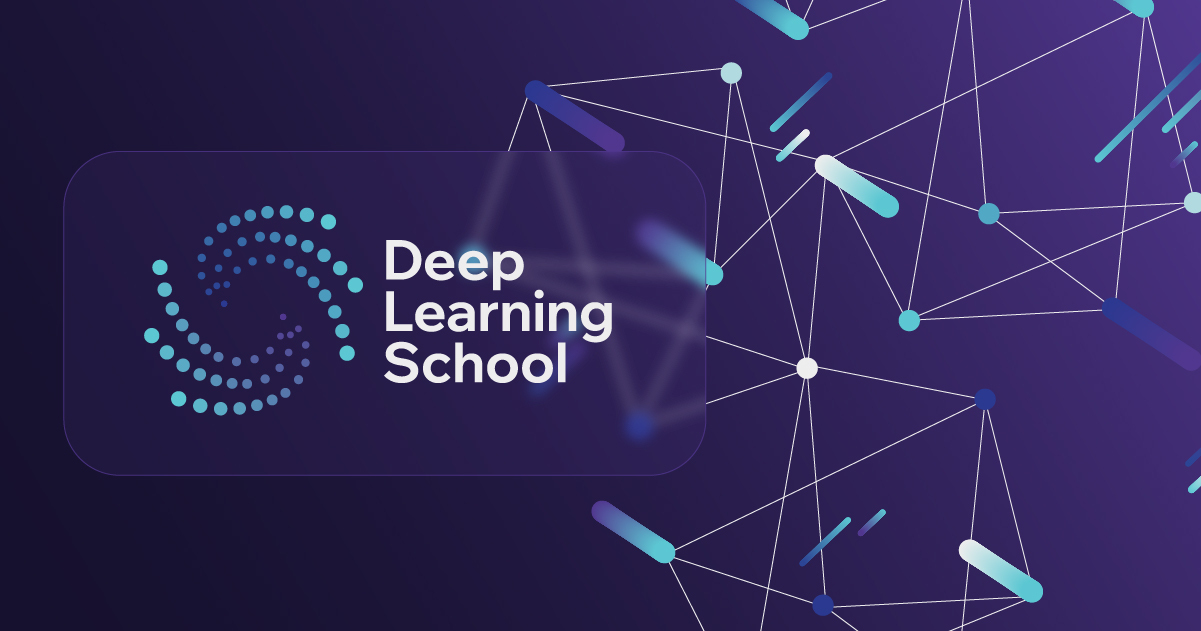

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание по теме "Механизм внимания.</b></h1>


Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

In [2]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Union, List, Optional, Dict, Any

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [7]:
DATA_PATH = "data_problems_translated.csv"

df = pd.read_csv(DATA_PATH)

print("Столбцы датасета:")
print(df.columns.tolist())

df.columns = (
    df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

TEXT_COLUMN = "problem_text"
LABEL_COLUMN = "topic"

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
df.head()

Столбцы датасета:
['Unnamed: 0', 'problem_text', 'topic']


,problem_text,topic
0,To prove that the sum of the numbers of the ex...,number_theory
1,( b) Will the statement of the previous challe...,number_theory
2,The quadratic three-member graph with the coef...,polynoms
3,Can you draw on the surface of Rubik's cube a ...,combinatorics
4,"Dima, who came from Vrunlandia, said that ther...",graphs


In [25]:
with pd.option_context('display.max_colwidth', None):
    print(df.iloc[3])

problem_text    Can you draw on the surface of Rubik's cube a closed path that passes through each square exactly once (the top of the square does not pass through)?
topic                                                                                                                                                   combinatorics
label                                                                                                                                                               0
Name: 3, dtype: object


In [8]:
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df[LABEL_COLUMN].astype(str))
num_labels = len(label_encoder.classes_)

train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["label"]
)

class MathDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=256):
        self.texts = frame[TEXT_COLUMN].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        item = self.tokenizer(
            self.texts[idx], max_length=self.max_length,
            truncation=True, padding="max_length", return_tensors="pt"
        )
        return {
            "input_ids": item["input_ids"].squeeze(0),
            "attention_mask": item["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }

tokenizer = AutoTokenizer.from_pretrained("cointegrated/rubert-tiny2")
train_dataset = MathDataset(train_df, tokenizer)
val_dataset = MathDataset(val_df, tokenizer)
train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [9]:
class TransformerClassificationModel(nn.Module):
    def __init__(
        self,
        base_transformer_model: Union[str, nn.Module],
        num_labels: int,
        dropout: float = 0.2,
    ):
        super().__init__()
        if isinstance(base_transformer_model, str):
            self.backbone = AutoModel.from_pretrained(
                base_transformer_model, output_attentions=True
            )
        else:
            self.backbone = base_transformer_model
            if hasattr(self.backbone, "config"):
                self.backbone.config.output_attentions = True

        hidden_size = getattr(self.backbone.config, "hidden_size", None)
        if hidden_size is None:
            hidden_size = getattr(self.backbone.config, "dim", None)
        if hidden_size is None:
            raise ValueError("Не удалось определить размер скрытого слоя backbone.")

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_labels)
        self.num_labels = num_labels

    def forward(self, input_ids=None, attention_mask=None, **kwargs):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_attentions=True,
            return_dict=True,
            **kwargs,
        )
        pooled = outputs.last_hidden_state[:, 0]
        logits = self.classifier(self.dropout(pooled))
        return {
            "logits": logits,
            "attentions": outputs.attentions,
            "hidden_states": getattr(outputs, "hidden_states", None),
        }

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [10]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    return model

### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [11]:
def train_transformer(
    transformer_model,
    train_dataloader,
    val_dataloader=None,
    freeze_backbone=True,
    epochs=3,
    learning_rate=2e-5,
    head_learning_rate=1e-3,
    weight_decay=0.01,
):
    model = copy.deepcopy(transformer_model)
    if freeze_backbone:
        freeze_backbone_function(model)
    else:
        for parameter in model.backbone.parameters():
            parameter.requires_grad = True

    model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        [
            {"params": [p for p in model.backbone.parameters() if p.requires_grad],
             "lr": learning_rate},
            {"params": model.classifier.parameters(), "lr": head_learning_rate},
        ],
        weight_decay=weight_decay,
    )
    total_steps = max(1, epochs * len(train_dataloader))
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch in train_dataloader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop("labels", batch.pop("label", None))
            if labels is None:
                raise KeyError("В batch должен быть ключ 'labels' или 'label'.")
            optimizer.zero_grad()
            logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch.get("attention_mask")
            )["logits"]
            loss = criterion(logits, labels.long())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()

        history["train_loss"].append(running_loss / max(1, len(train_dataloader)))

        if val_dataloader is not None:
            model.eval()
            val_loss, predictions, targets = 0.0, [], []
            with torch.no_grad():
                for batch in val_dataloader:
                    batch = {k: v.to(DEVICE) for k, v in batch.items()}
                    labels = batch.pop("labels", batch.pop("label", None))
                    logits = model(
                        input_ids=batch["input_ids"],
                        attention_mask=batch.get("attention_mask")
                    )["logits"]
                    val_loss += criterion(logits, labels.long()).item()
                    predictions.extend(logits.argmax(dim=1).cpu().tolist())
                    targets.extend(labels.cpu().tolist())
            history["val_loss"].append(val_loss / max(1, len(val_dataloader)))
            history["val_accuracy"].append(accuracy_score(targets, predictions))

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"train_loss={history['train_loss'][-1]:.4f}"
            + (f", val_loss={history['val_loss'][-1]:.4f}, "
               f"val_acc={history['val_accuracy'][-1]:.4f}"
               if val_dataloader is not None else "")
        )

    model.eval()
    model.history = history
    return model

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [12]:
MODEL_NAME = "cointegrated/rubert-tiny2"

rubert_tiny_transformer_model = TransformerClassificationModel(
    MODEL_NAME, num_labels=num_labels
)
rubert_tiny_finetuned_with_freezed_backbone = train_transformer(
    rubert_tiny_transformer_model,
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    freeze_backbone=True,
    epochs=3,
)

rubert_tiny_transformer_model_full = TransformerClassificationModel(
    MODEL_NAME, num_labels=num_labels
)
rubert_tiny_full_finetuned = train_transformer(
    rubert_tiny_transformer_model_full,
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    freeze_backbone=False,
    epochs=3,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: train_loss=1.4575, val_loss=1.2072, val_acc=0.5469
Epoch 2/3: train_loss=1.1733, val_loss=1.1408, val_acc=0.5678
Epoch 3/3: train_loss=1.1303, val_loss=1.1269, val_acc=0.5697


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: train_loss=1.3330, val_loss=1.0753, val_acc=0.5886
Epoch 2/3: train_loss=1.0391, val_loss=1.0058, val_acc=0.6123
Epoch 3/3: train_loss=0.9644, val_loss=0.9901, val_acc=0.6066


### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [13]:
MATHBERT_NAME = "tbs17/MathBert"
mathbert_tokenizer_for_training = AutoTokenizer.from_pretrained(MATHBERT_NAME)
mathbert_train_loader = DataLoader(
    MathDataset(train_df, mathbert_tokenizer_for_training),
    batch_size=16, shuffle=True
)
mathbert_val_loader = DataLoader(
    MathDataset(val_df, mathbert_tokenizer_for_training),
    batch_size=32, shuffle=False
)

mathbert_model = TransformerClassificationModel(
    MATHBERT_NAME, num_labels=num_labels
)
mathbert_finetuned_frozen = train_transformer(
    mathbert_model, mathbert_train_loader, mathbert_val_loader,
    freeze_backbone=True, epochs=3
)

mathbert_model_full = TransformerClassificationModel(
    MATHBERT_NAME, num_labels=num_labels
)
mathbert_finetuned_full = train_transformer(
    mathbert_model_full, mathbert_train_loader, mathbert_val_loader,
    freeze_backbone=False, epochs=3
)


results = {
    "RuBERT frozen": rubert_tiny_finetuned_with_freezed_backbone.history["val_accuracy"][-1],
    "RuBERT full": rubert_tiny_full_finetuned.history["val_accuracy"][-1],
    "MathBERT frozen": mathbert_finetuned_frozen.history["val_accuracy"][-1],
    "MathBERT full": mathbert_finetuned_full.history["val_accuracy"][-1],
}
pd.Series(results, name="validation accuracy").sort_values(ascending=False)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  441MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (3 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: train_loss=1.2539, val_loss=1.0856, val_acc=0.5943
Epoch 2/3: train_loss=0.8918, val_loss=1.0845, val_acc=0.5839
Epoch 3/3: train_loss=0.6591, val_loss=1.0971, val_acc=0.5744


,validation accuracy
RuBERT full,0.606635
MathBERT full,0.574408
RuBERT frozen,0.569668
MathBERT frozen,0.561137


### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [14]:
def draw_first_layer_attention_maps(
    attention_head_ids: List[int],
    text: str,
    model: TransformerClassificationModel,
    tokenizer,
    max_length: int = 128,
):
    model.eval()
    encoded = tokenizer(
        text, return_tensors="pt", truncation=True,
        max_length=max_length, padding=False
    ).to(DEVICE)

    model.to(DEVICE)
    with torch.no_grad():
        outputs = model(**encoded)

    attentions = outputs["attentions"]
    if attentions is None:
        raise RuntimeError("Backbone не вернул attention weights.")
    first_layer = attentions[0][0].detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0].cpu())

    for head_id in attention_head_ids:
        if not 0 <= head_id < first_layer.shape[0]:
            raise ValueError(
                f"Номер головы {head_id} вне диапазона 0..{first_layer.shape[0]-1}"
            )
        plt.figure(figsize=(max(8, len(tokens) * 0.45), 7))
        sns.heatmap(
            first_layer[head_id],
            xticklabels=tokens,
            yticklabels=tokens,
            cmap="viridis",
            square=True
        )
        plt.title(f"Attention: first layer, head {head_id}")
        plt.xlabel("Ключевые токены")
        plt.ylabel("Токены-запросы")
        plt.xticks(rotation=90)
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5.


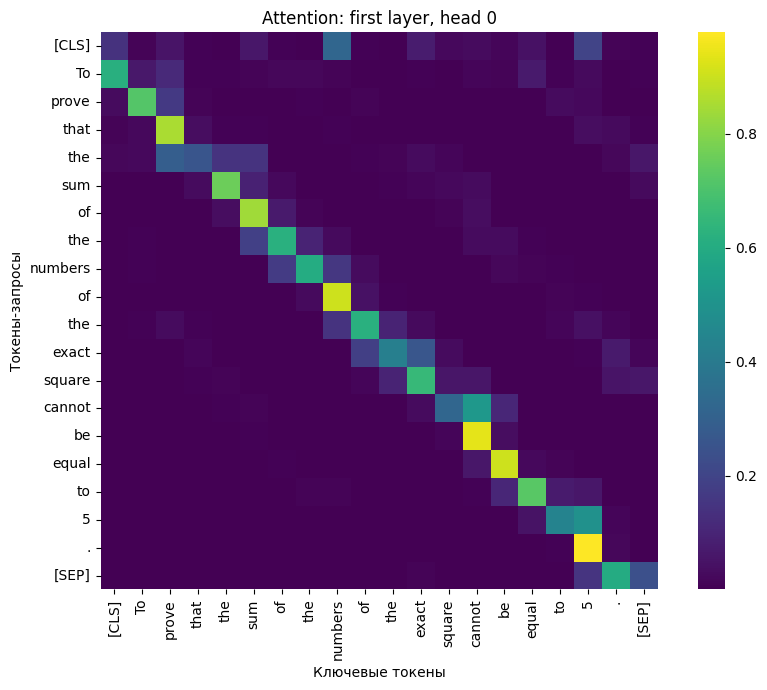

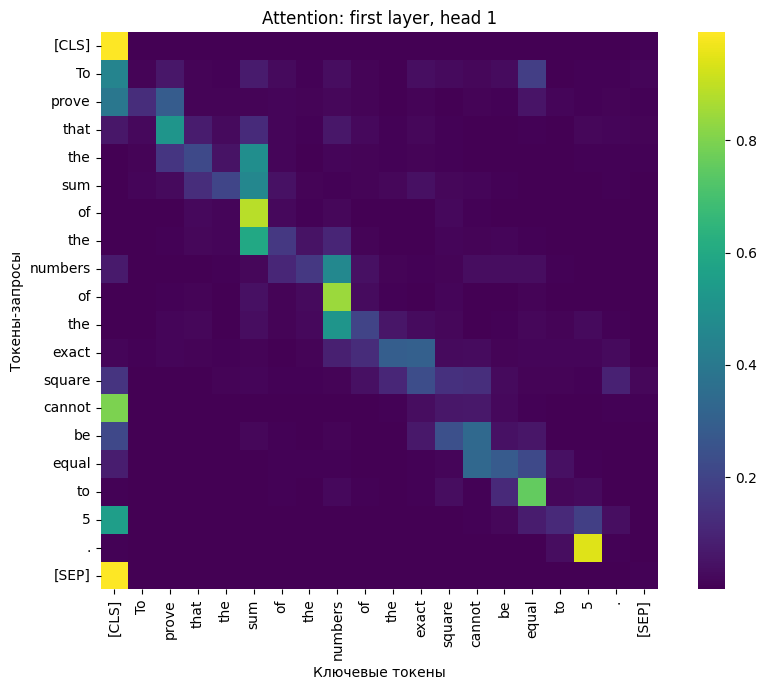

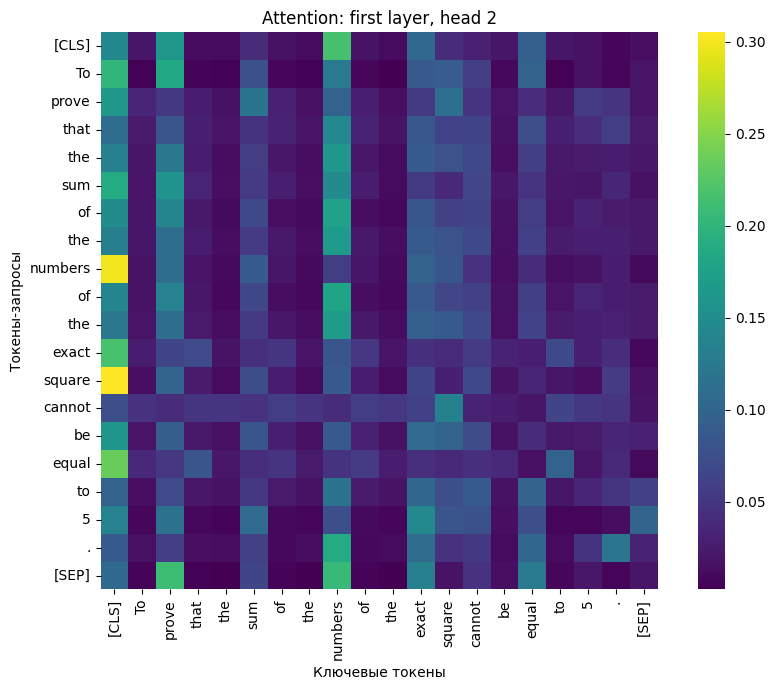

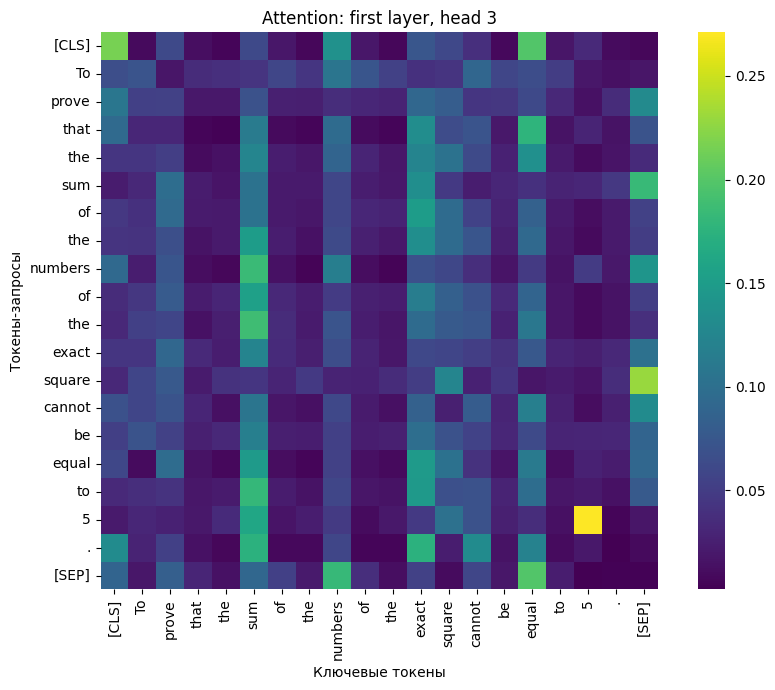

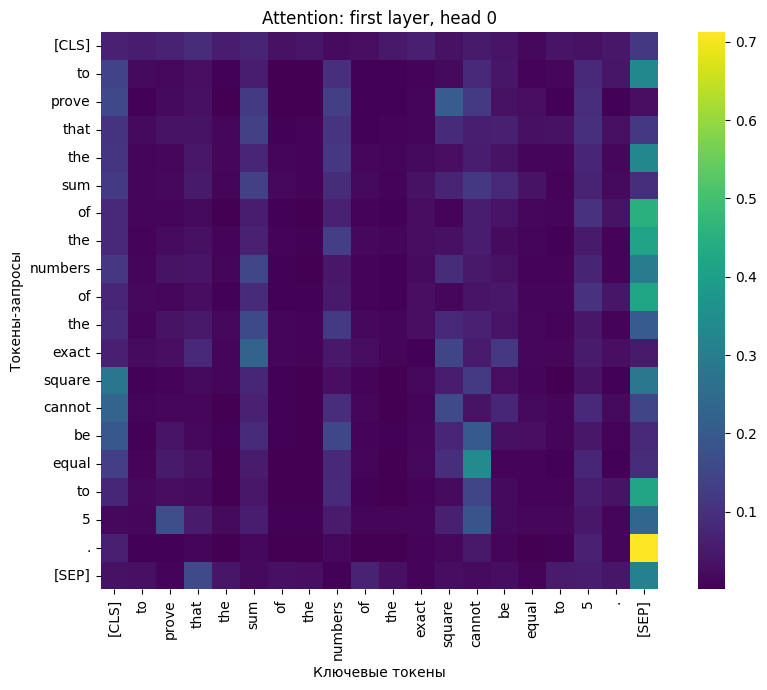

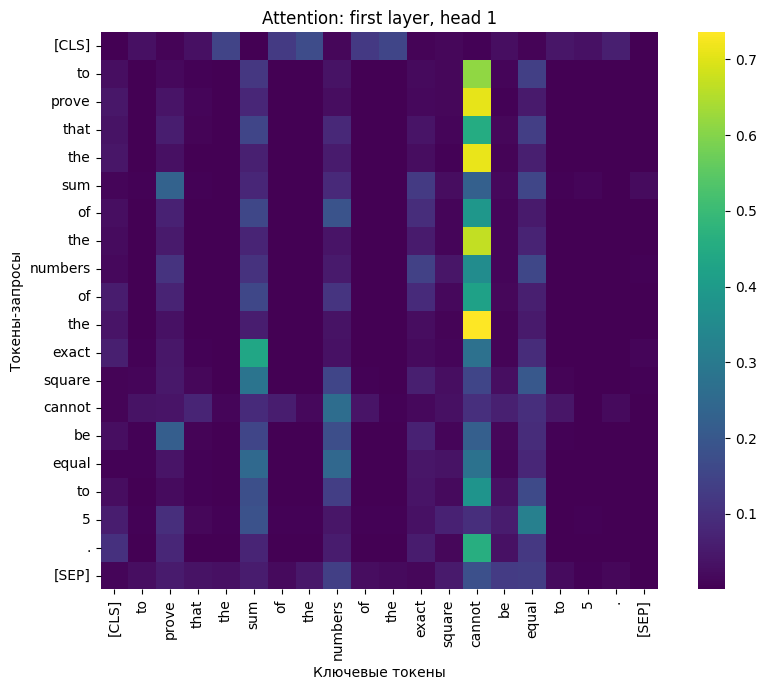

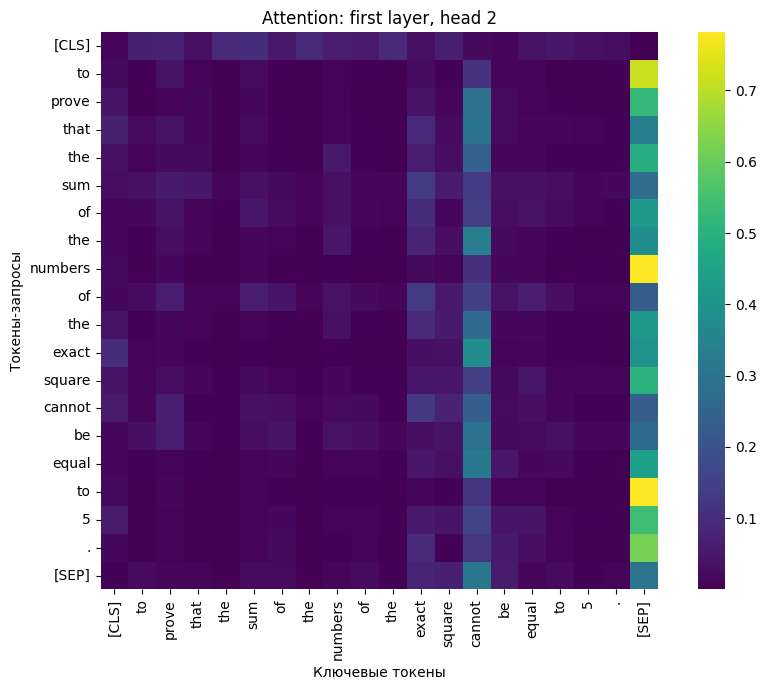

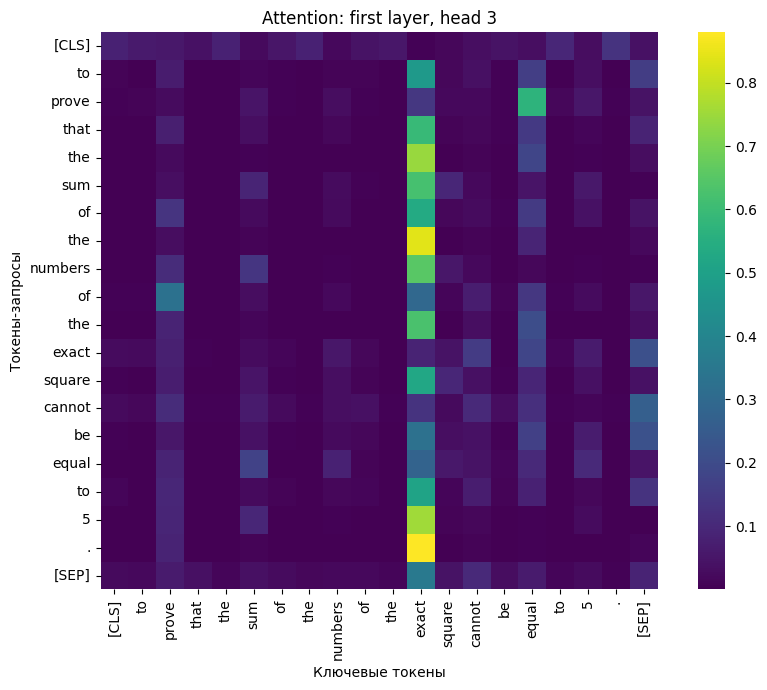

Текст: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.


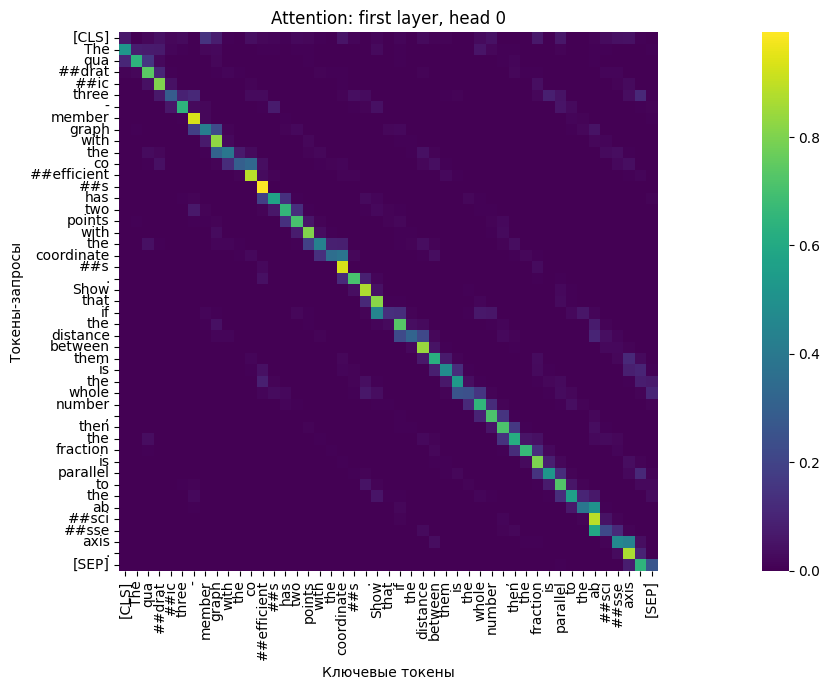

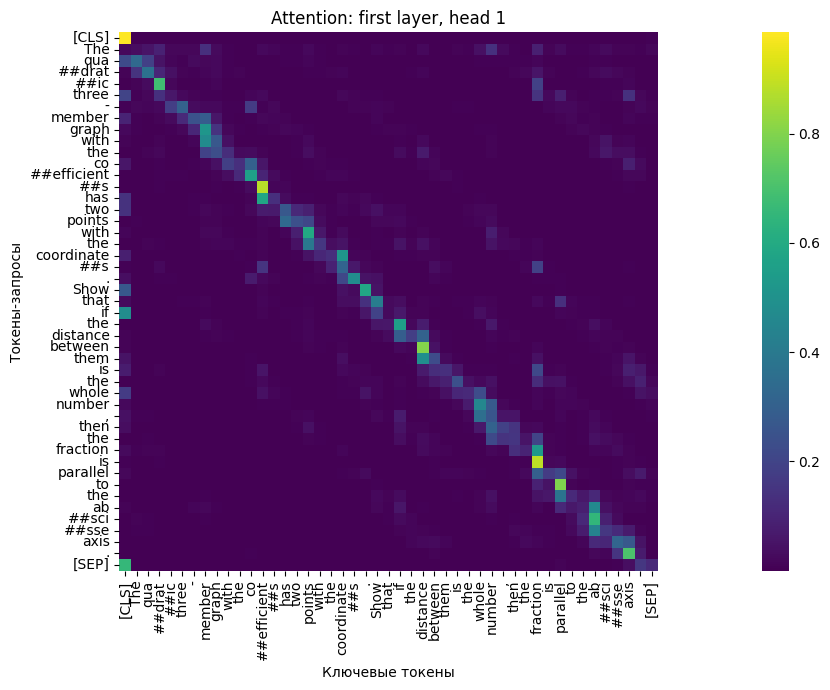

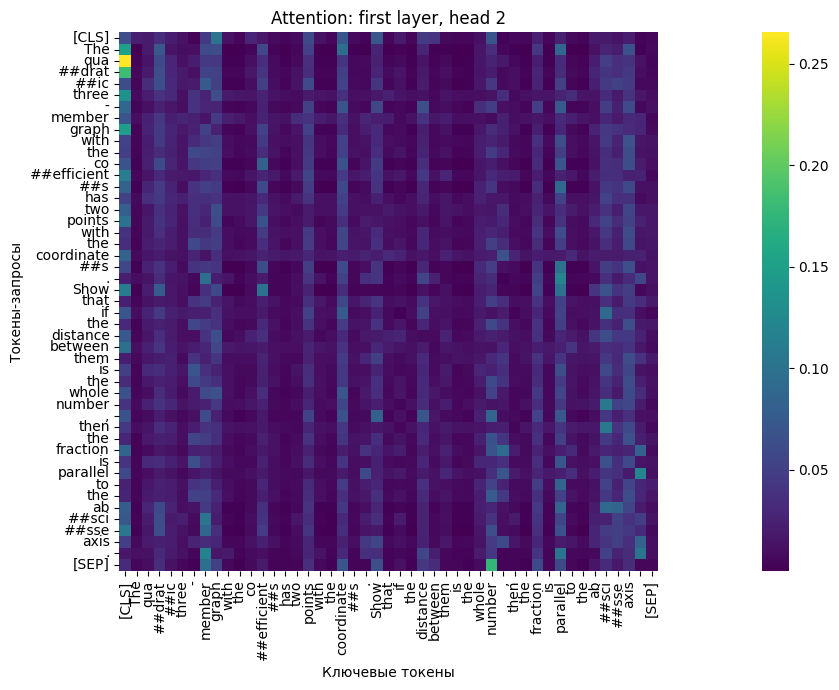

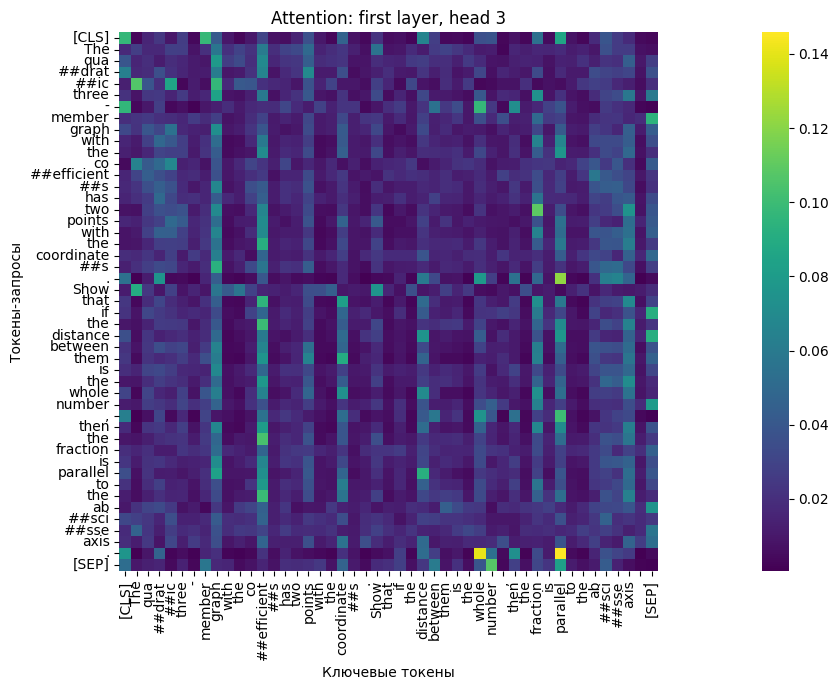

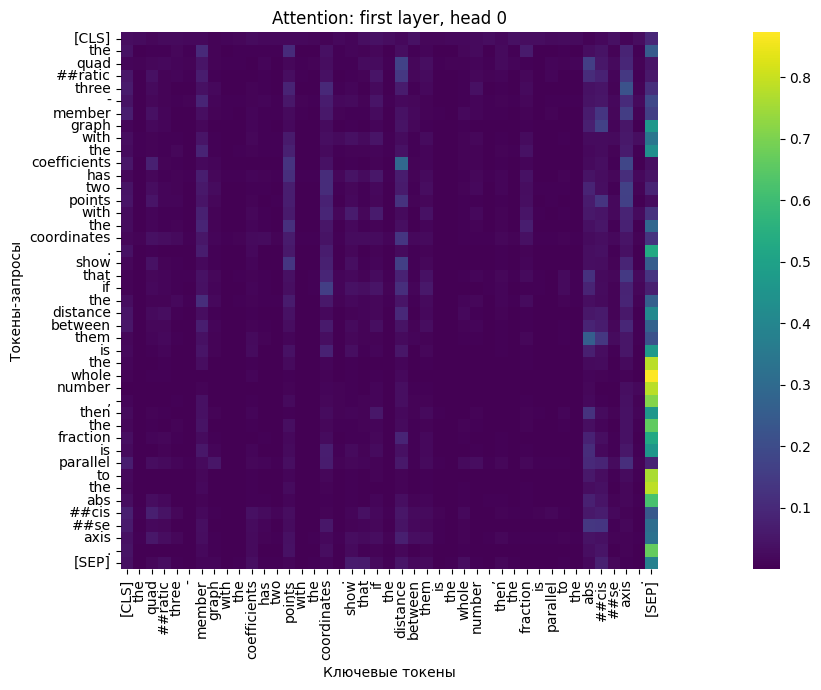

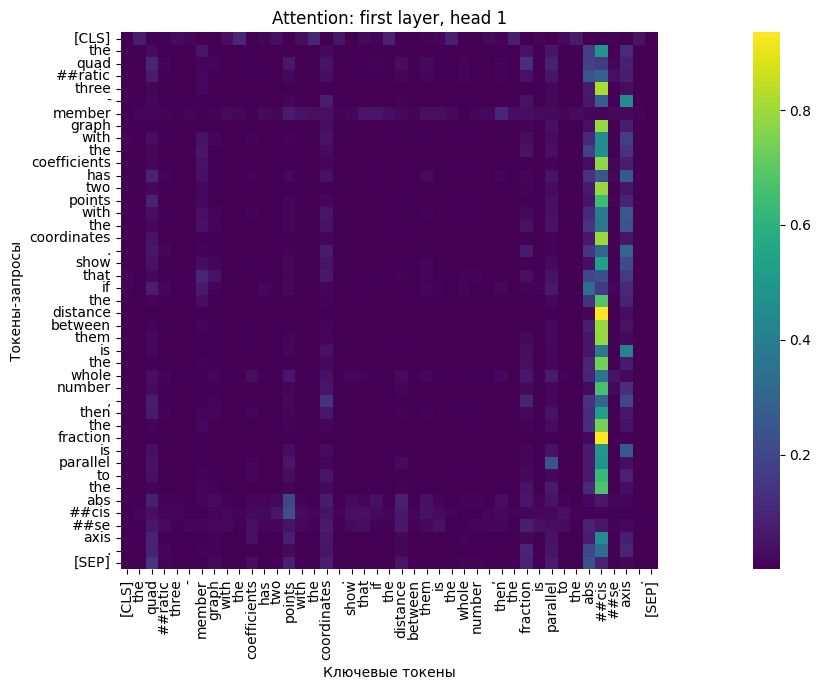

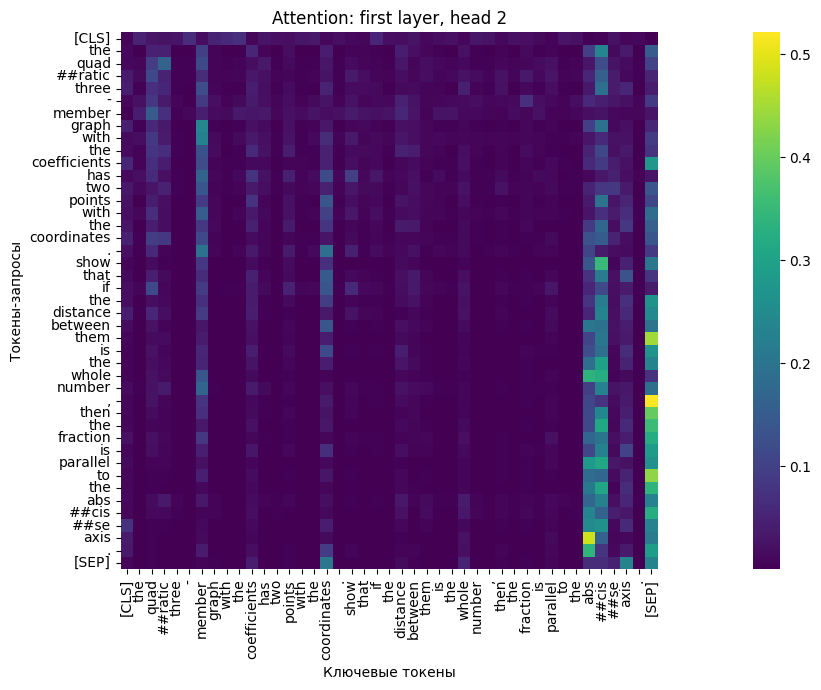

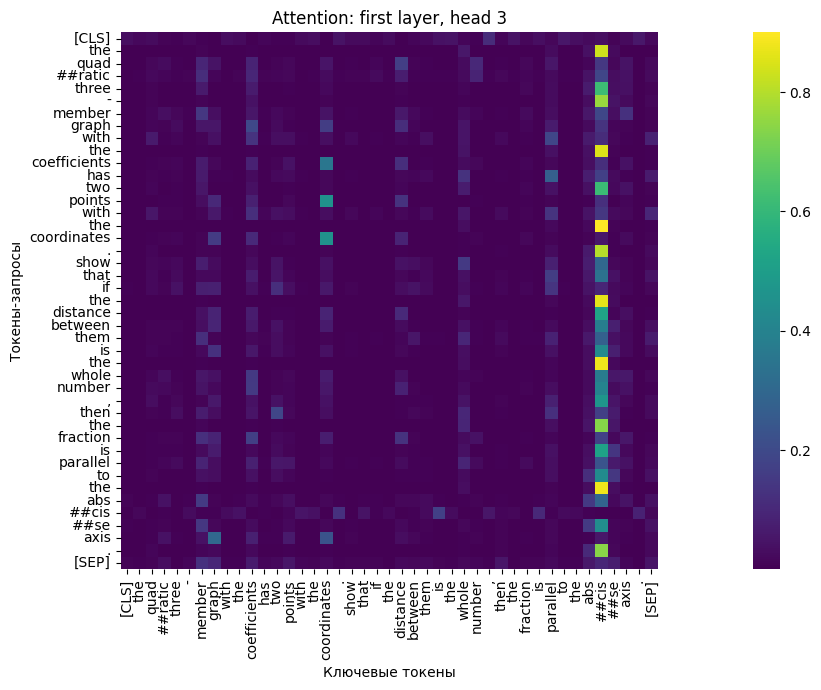

Текст: Can you draw on the surface of Rubik's cube a closed path that passes through each square exactly once (the top of the square does not pass through)?


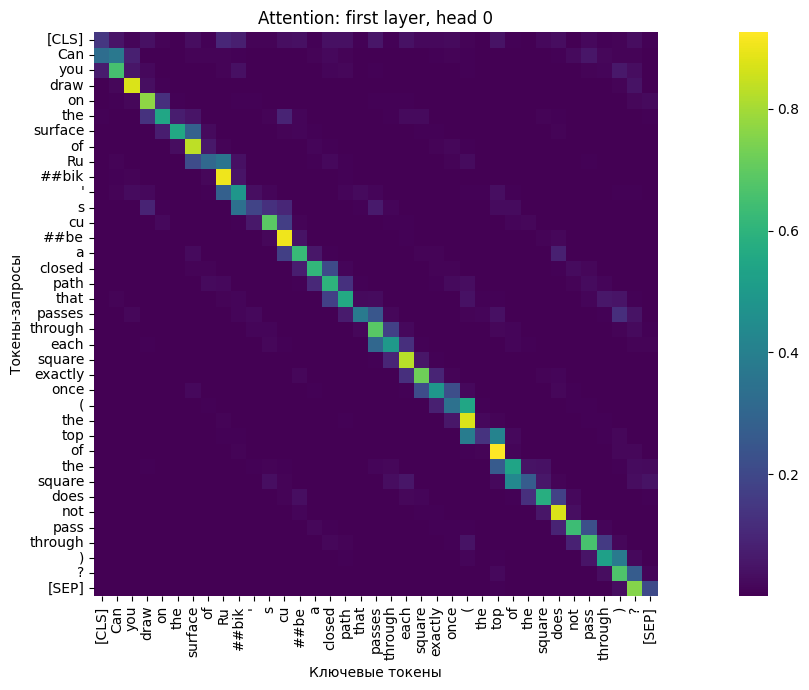

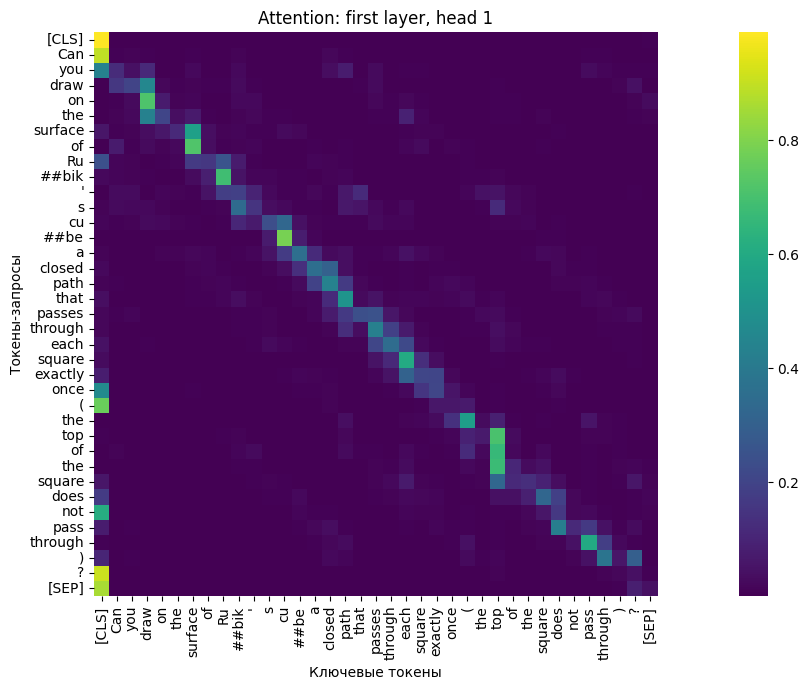

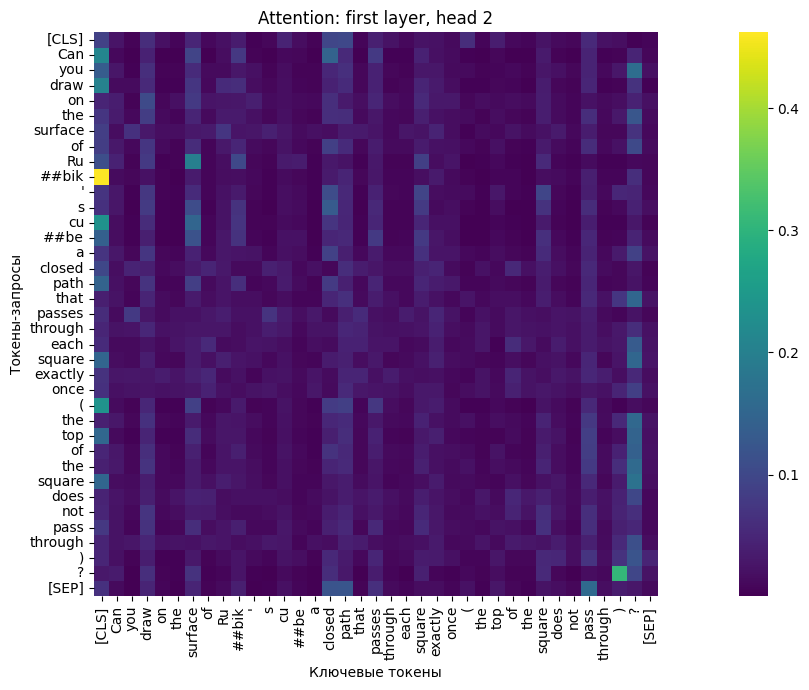

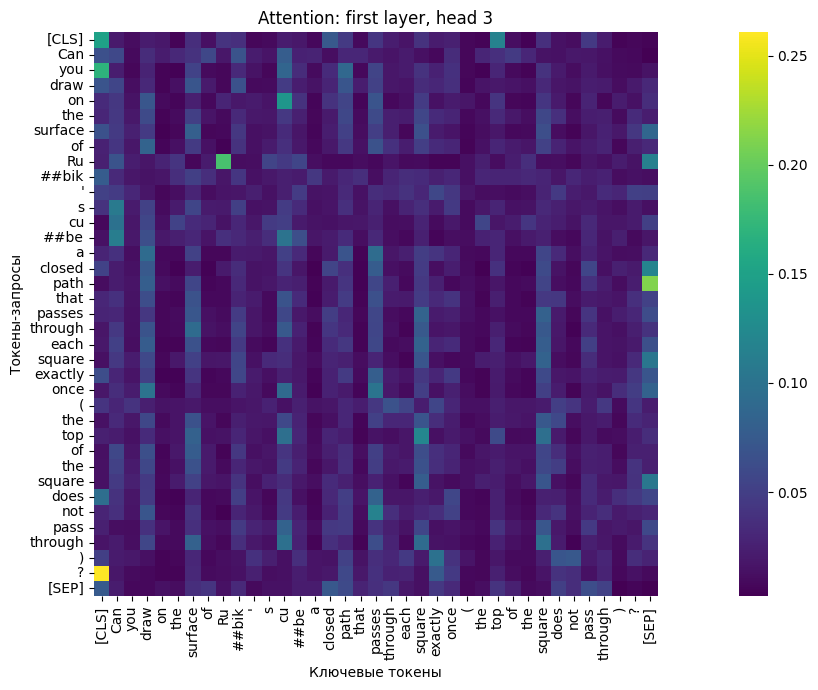

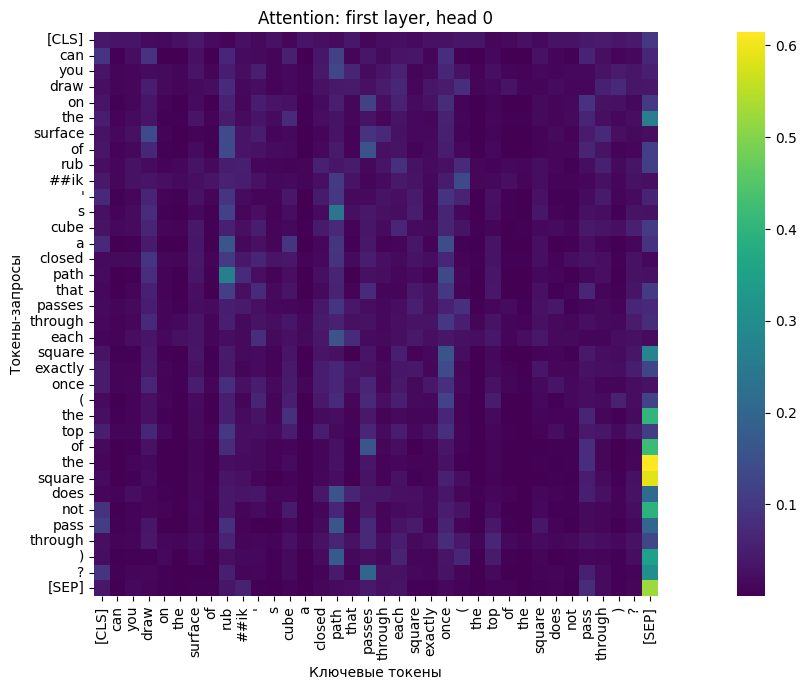

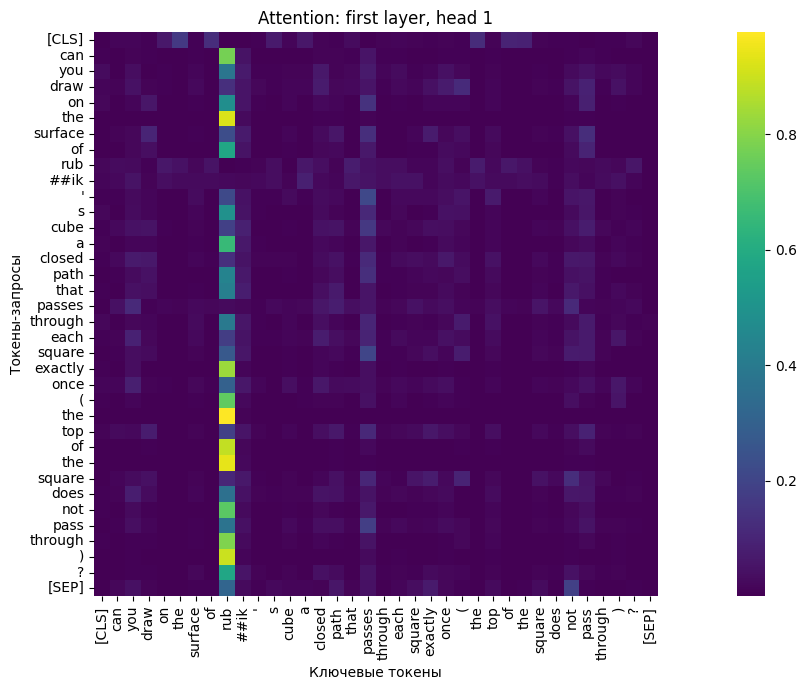

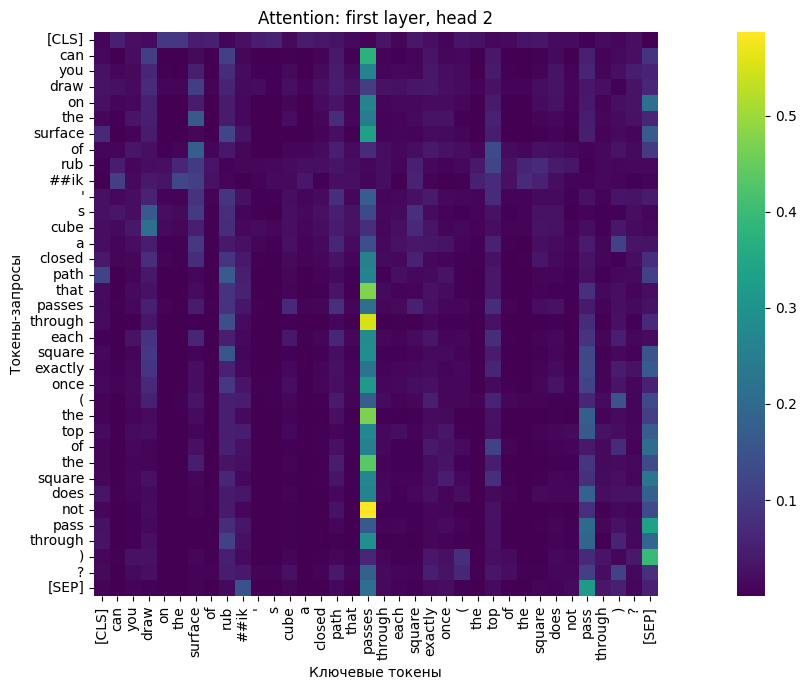

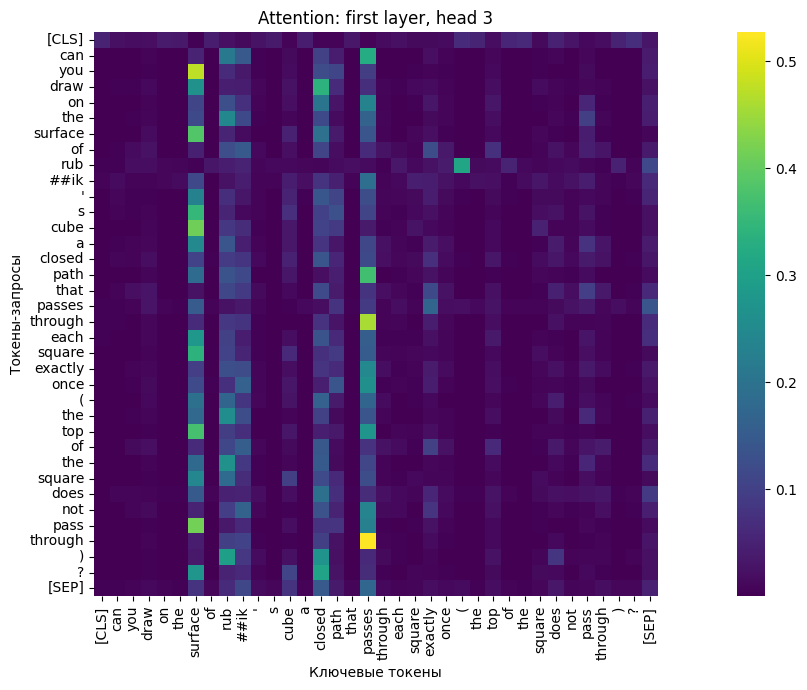

In [26]:
example_texts = [
    "To prove that the sum of the numbers of the exact square cannot be equal to 5.",
    "The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.",
    "Can you draw on the surface of Rubik's cube a closed path that passes through each square exactly once (the top of the square does not pass through)?",
]

rubert_tokenizer = AutoTokenizer.from_pretrained("cointegrated/rubert-tiny2")
mathbert_tokenizer = AutoTokenizer.from_pretrained("tbs17/MathBert")

rubert_before = TransformerClassificationModel(
    "cointegrated/rubert-tiny2", num_labels=num_labels
).to(DEVICE)
mathbert_before = TransformerClassificationModel(
    "tbs17/MathBert", num_labels=num_labels
).to(DEVICE)

for text in example_texts:
    print("Текст:", text)
    draw_first_layer_attention_maps([0, 1, 2, 3], text, rubert_before, rubert_tokenizer)
    draw_first_layer_attention_maps([0, 1, 2, 3], text, mathbert_before, mathbert_tokenizer)

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

Текст: To prove that the sum of the numbers of the exact square cannot be equal to 5.


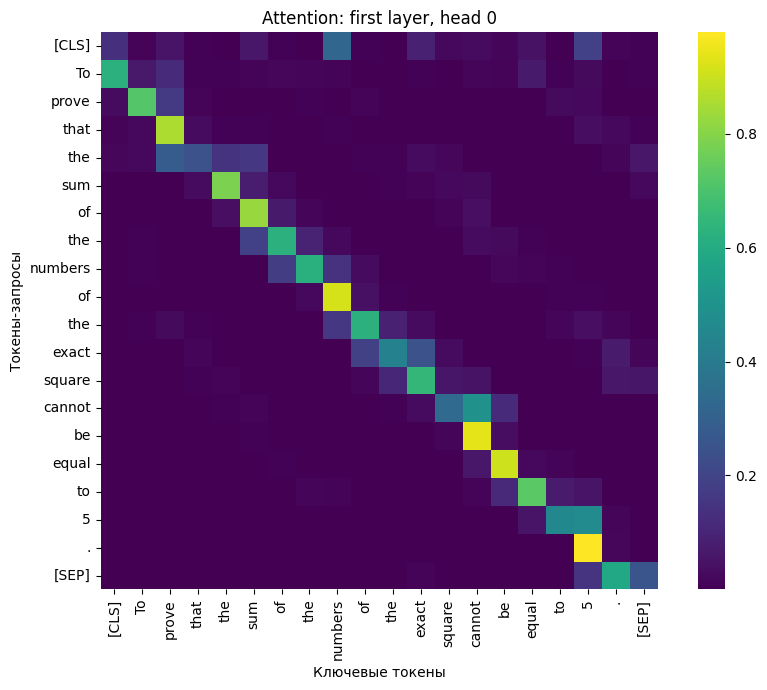

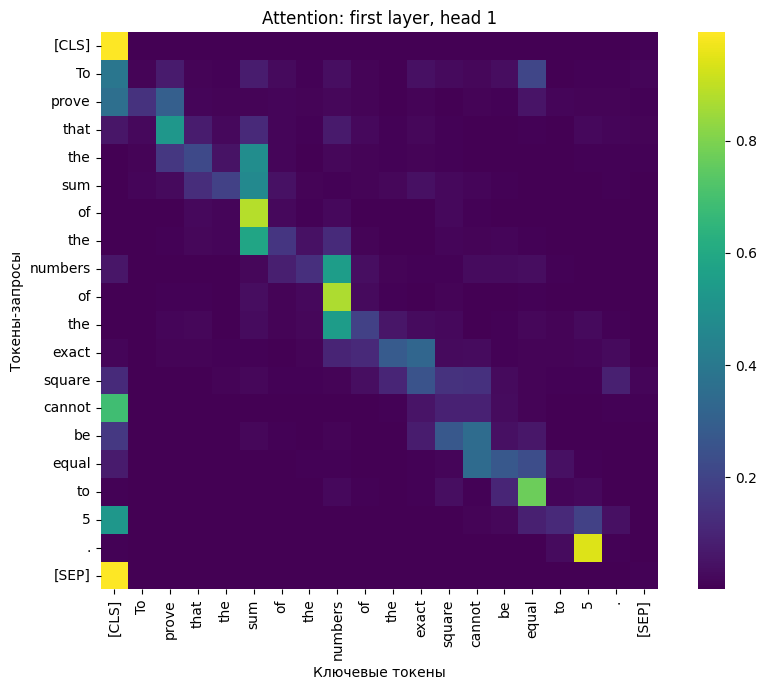

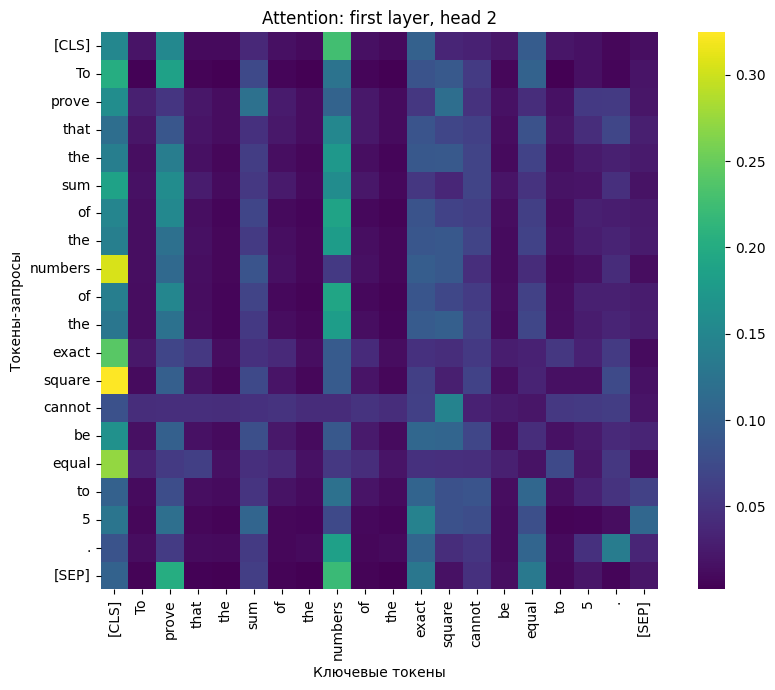

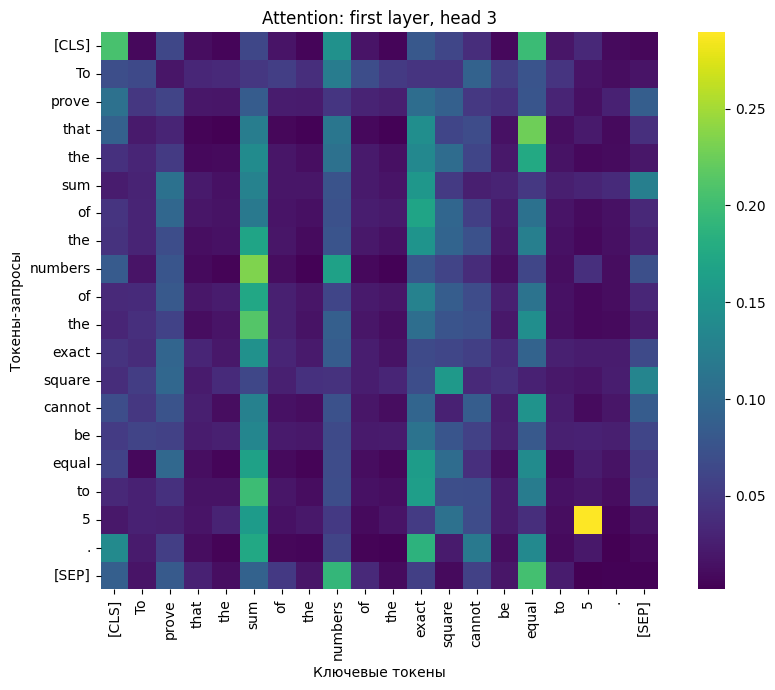

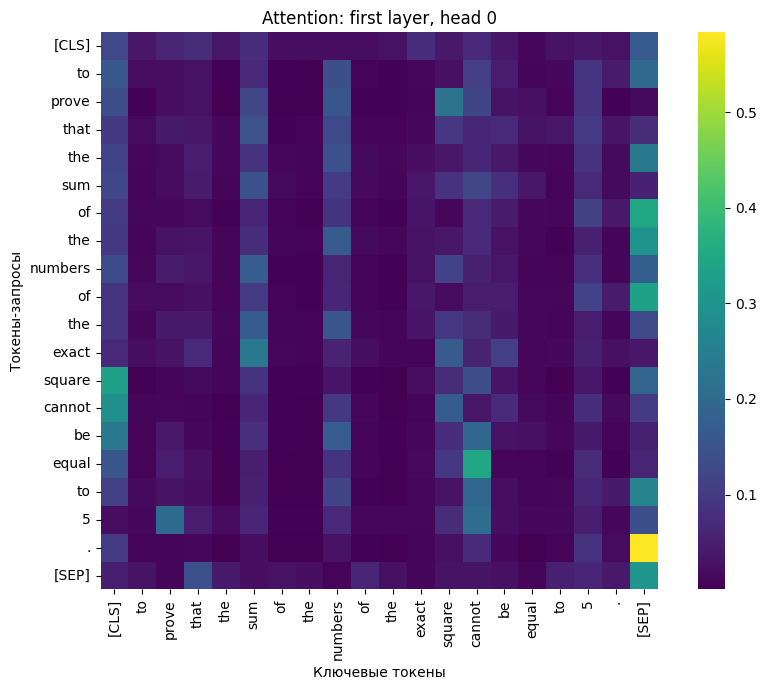

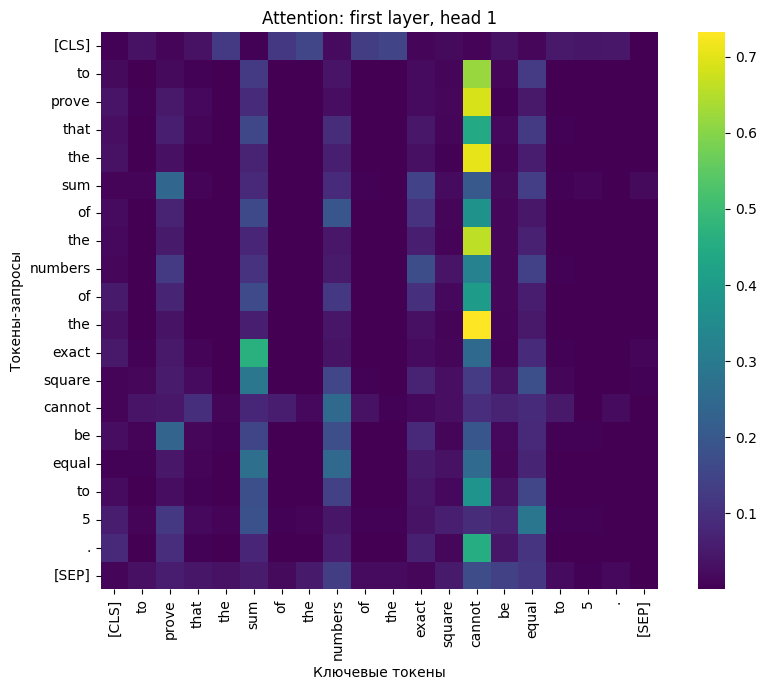

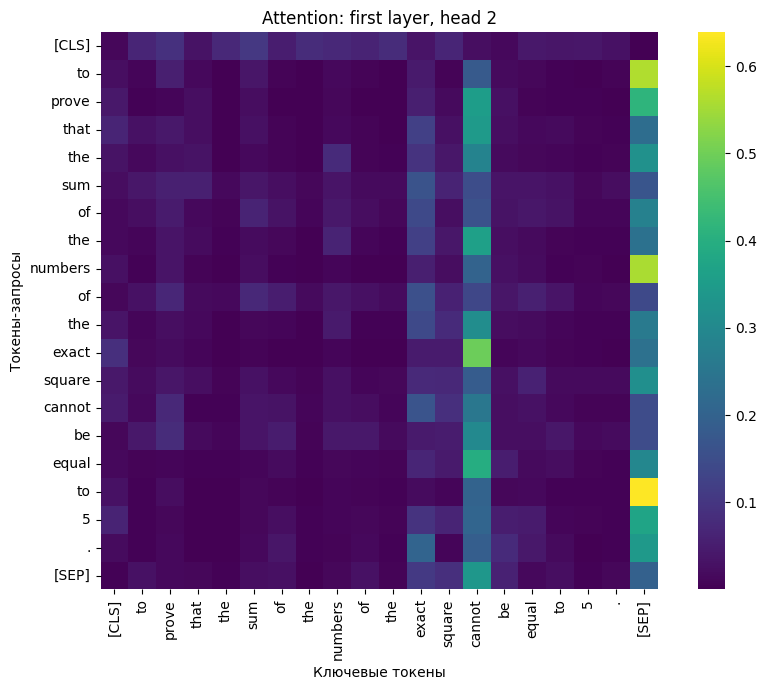

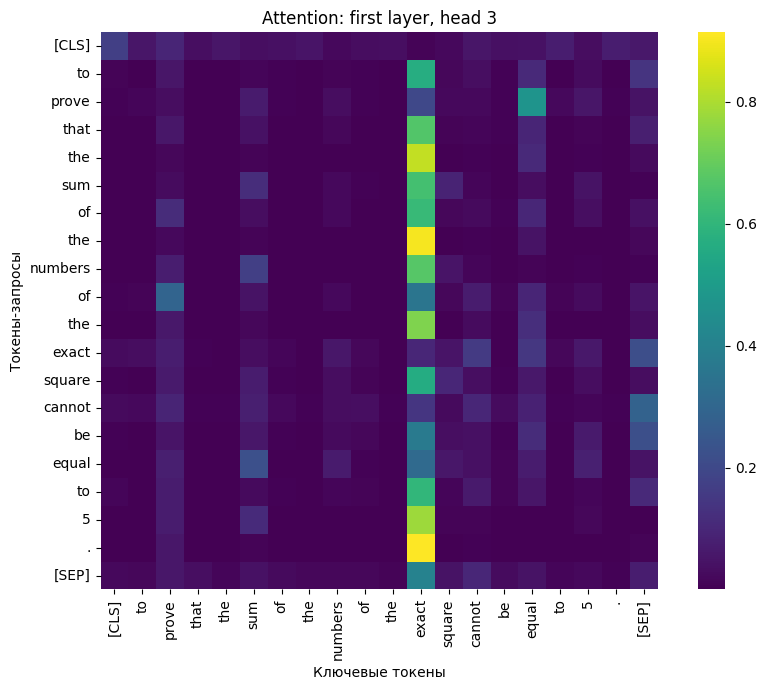

Текст: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.


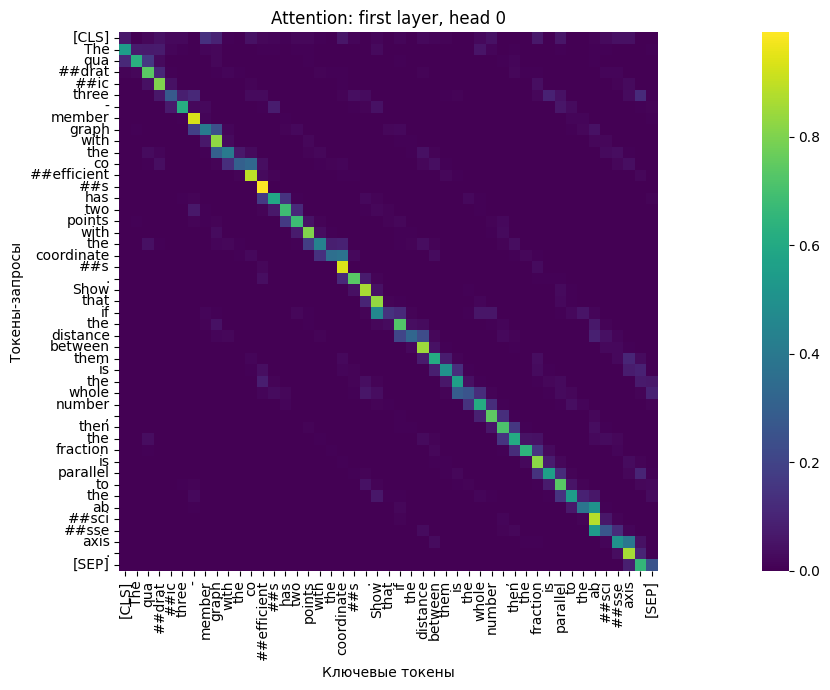

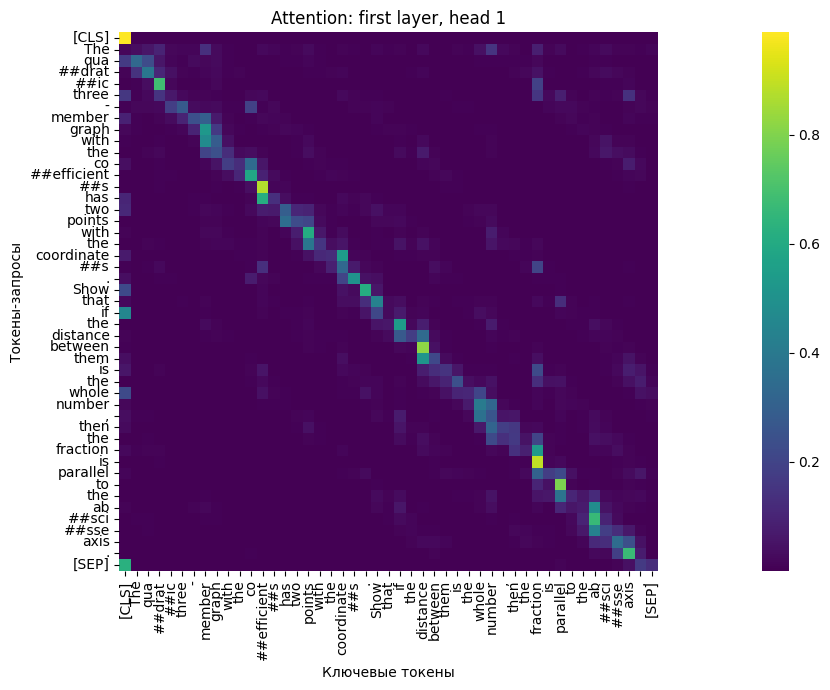

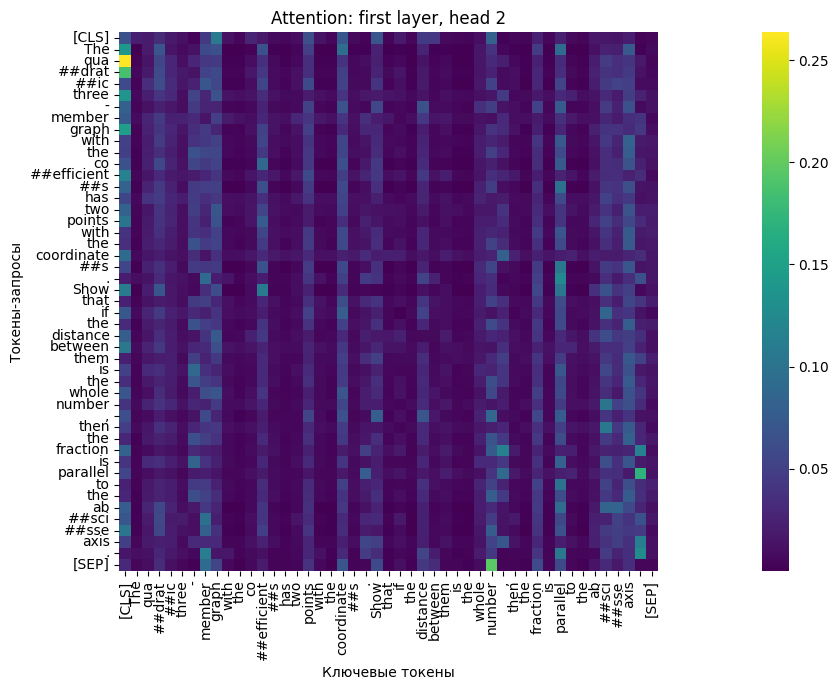

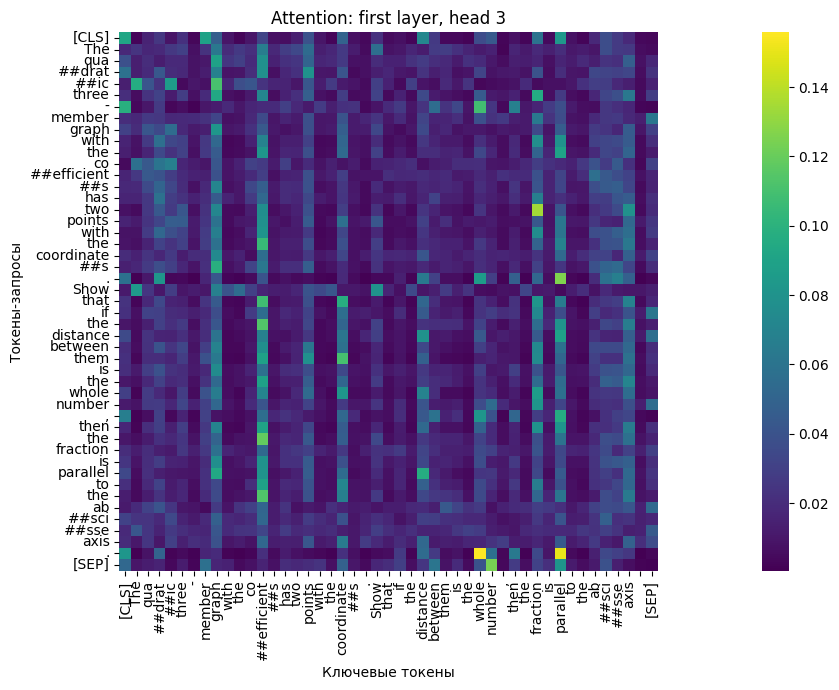

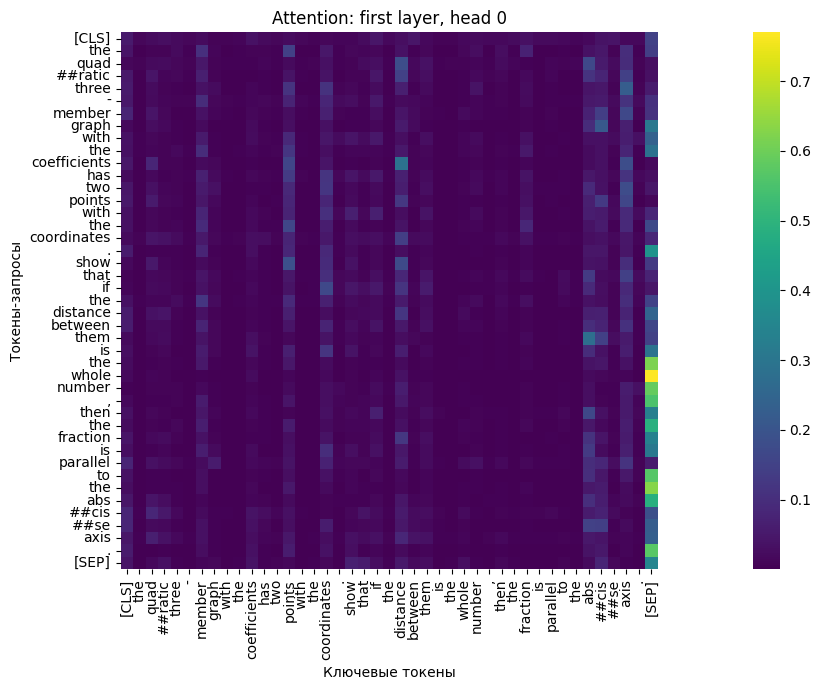

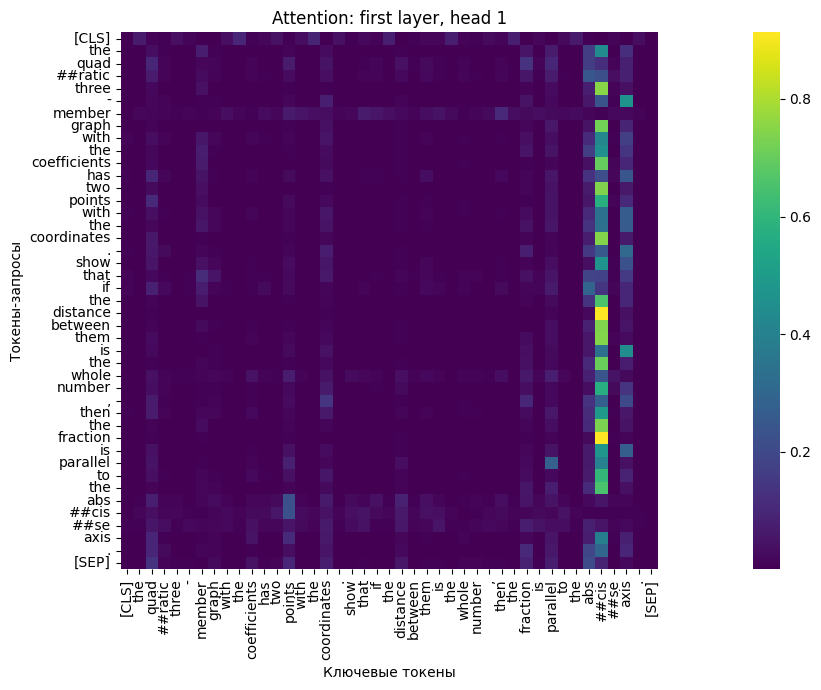

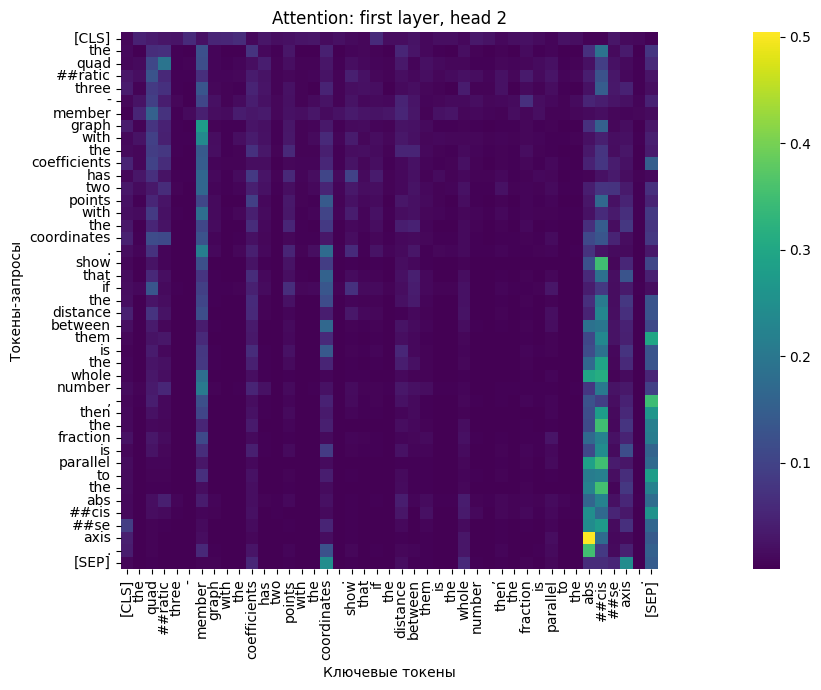

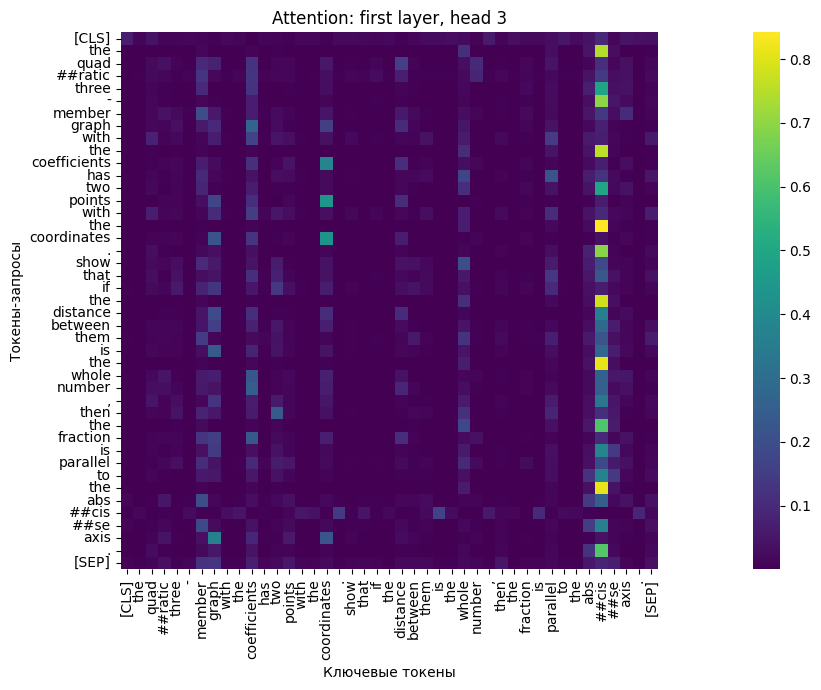

Текст: Can you draw on the surface of Rubik's cube a closed path that passes through each square exactly once (the top of the square does not pass through)?


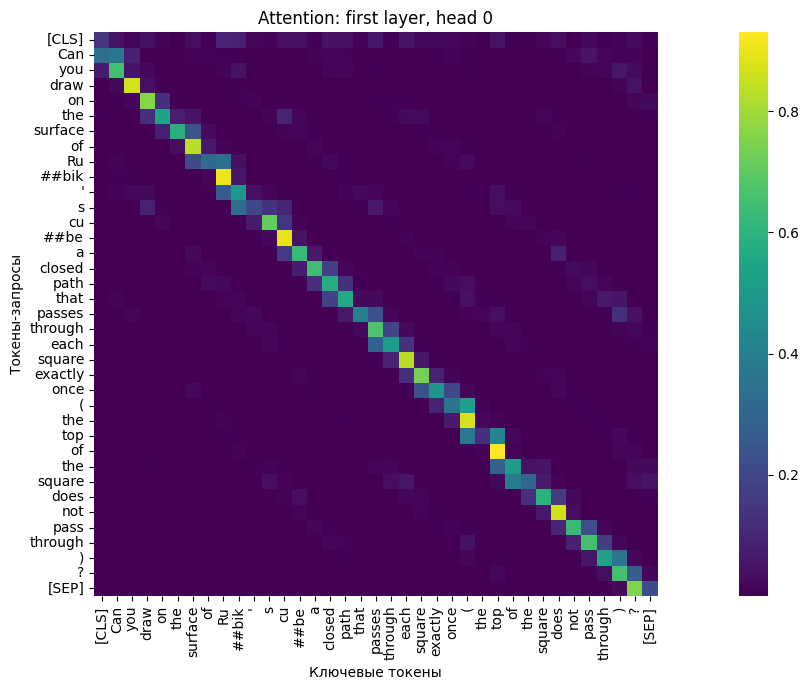

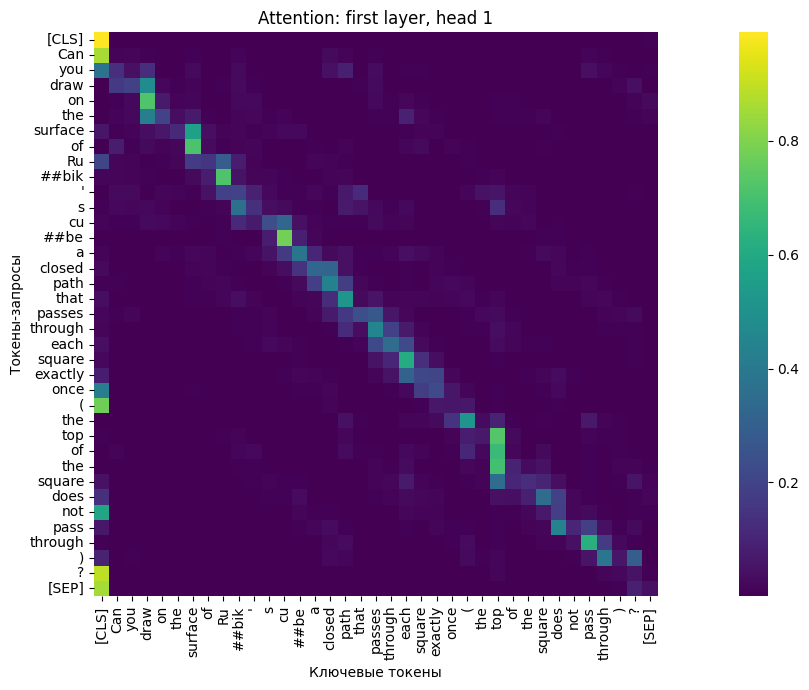

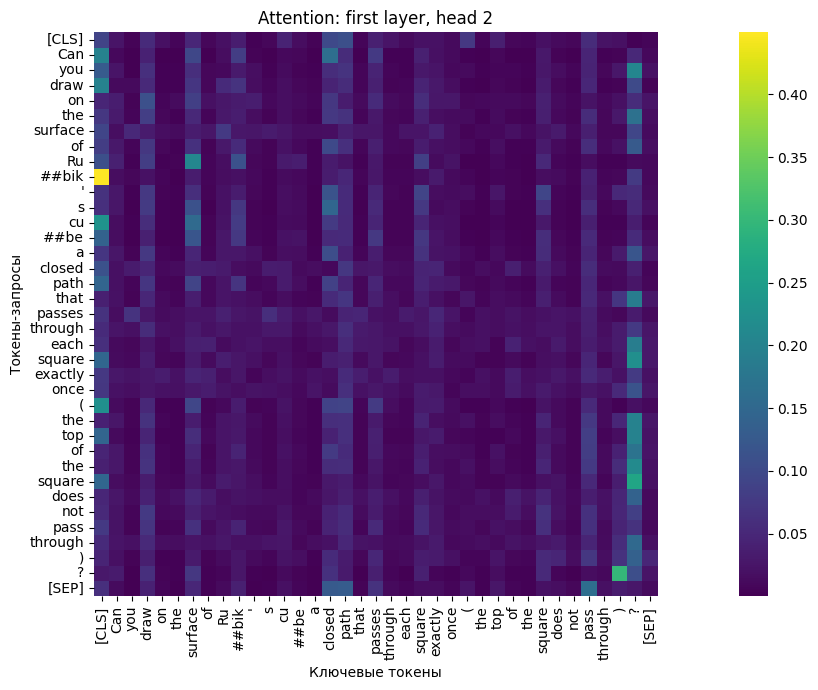

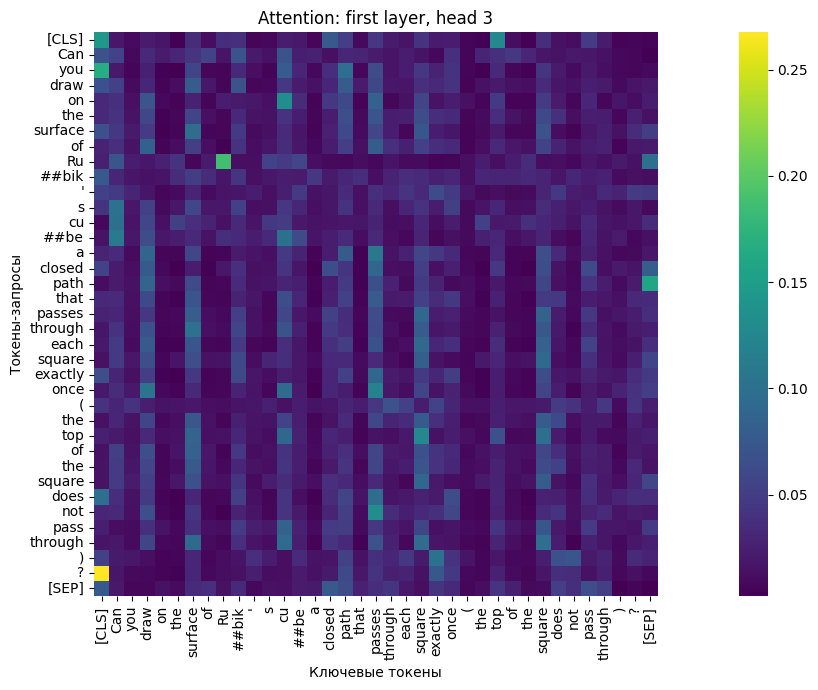

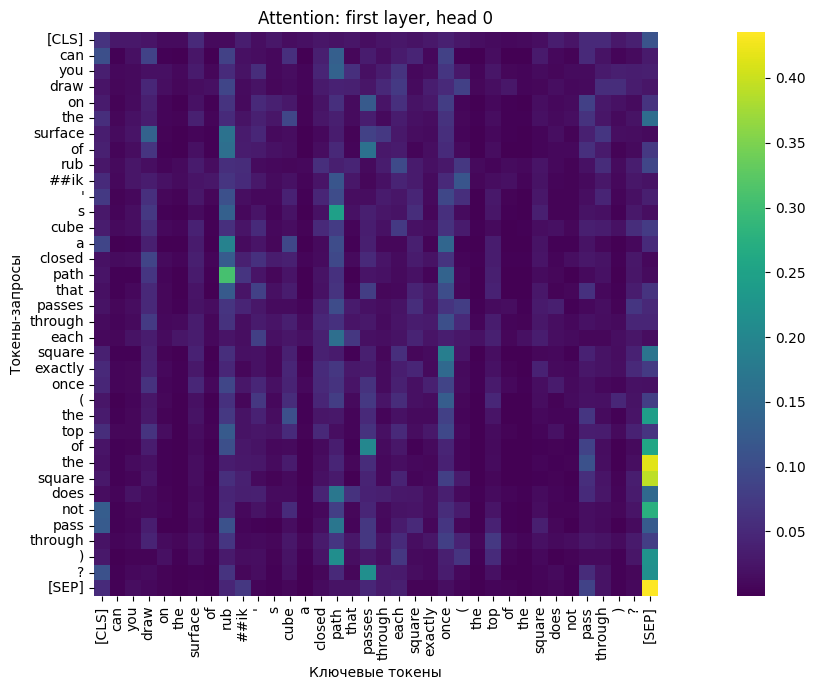

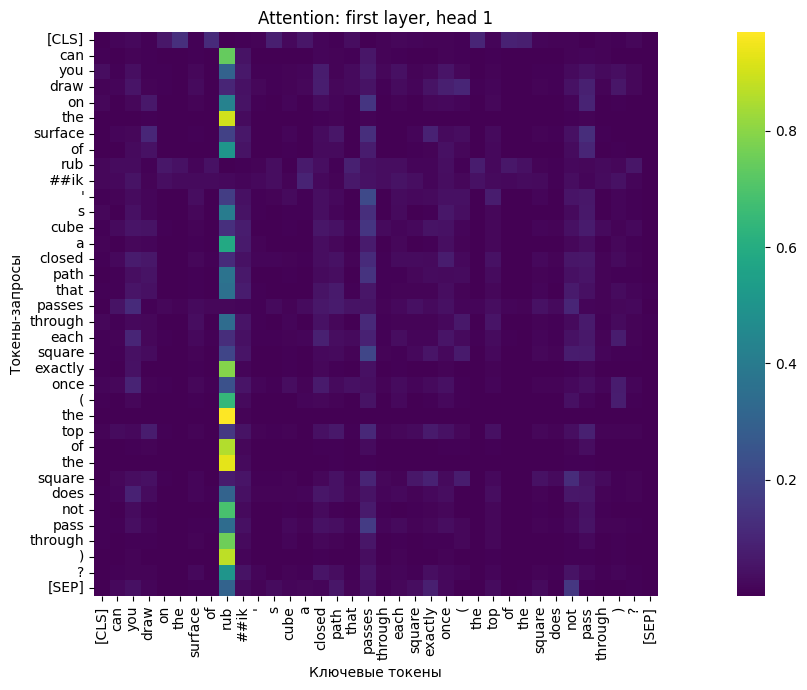

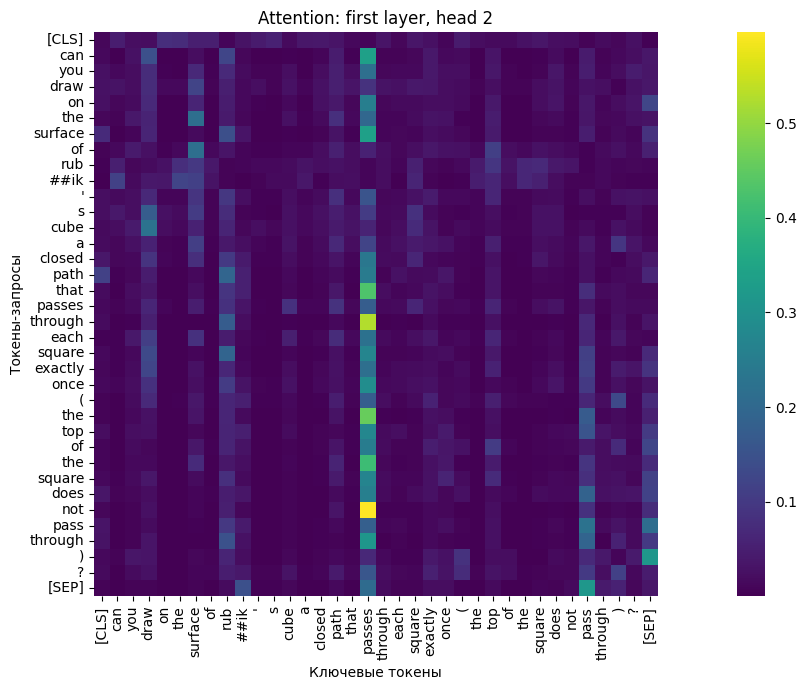

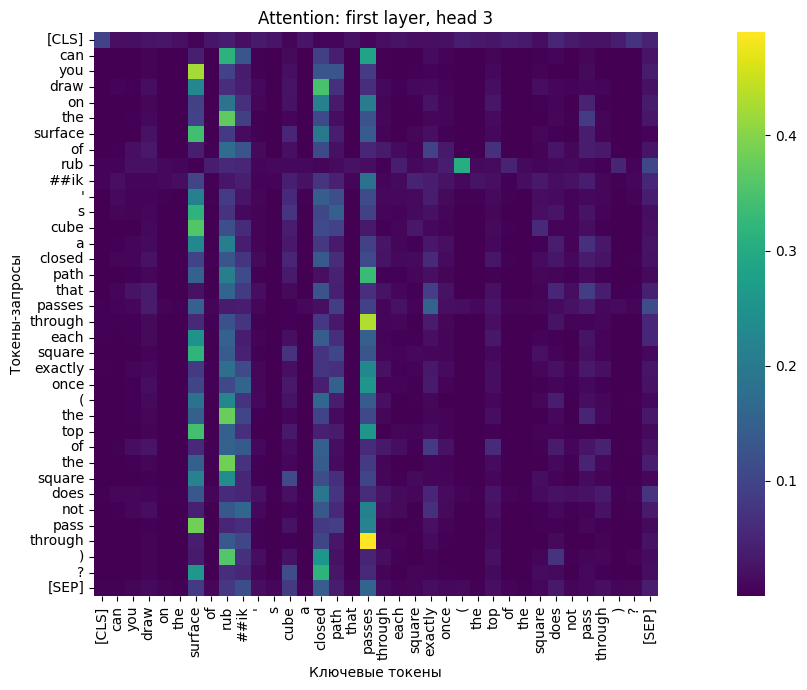

In [27]:
for text in example_texts:
    print("Текст:", text)
    draw_first_layer_attention_maps(
        [0, 1, 2, 3], text,
        rubert_tiny_full_finetuned, rubert_tokenizer
    )
    draw_first_layer_attention_maps(
        [0, 1, 2, 3], text,
        mathbert_finetuned_full, mathbert_tokenizer
    )